Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc, and save it to folder with name $date/

In [1]:
from utils.calibration import CalibrationSignal
from utils.imu_data import IMUData
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
iq0_path ='/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
# print('Calibrating the phase offsets between the three USRPs...')
# cal0 = CalibrationSignal(iq0_path, fc, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
# cal1 = CalibrationSignal(iq1_path, fc, tx_freq, sample_rate)
# cal2 = CalibrationSignal(iq2_path, fc, tx_freq, sample_rate)
# ref_sig_idx = cal0.get_all_refsigidx() # use the get_all_refsigidx() method to get the start and stop index of the reference signal
# phase_0 = cal0.get_refsig_phase(ref_sig_idx)
# phase_1 = cal1.get_refsig_phase(ref_sig_idx)
# phase_2 = cal2.get_refsig_phase(ref_sig_idx)

# t_end = ref_sig_idx[-1][1]/sample_rate  # use the stop time of the last ref sig as the duration of the file
# phase_offset_01 = np.unwrap(phase_0-phase_1)
# phase_offset_21 = np.unwrap(phase_2-phase_1)

# imu = IMUData(imu_path)
# imu_data = imu.read_imu_data()
# lat, lon, alt = imu.get_latlonalt_()
# lat_gt, lon_gt, alt_gt = np.mean(lat), np.mean(lon), np.mean(alt)
# print('ground truth lat, lon, alt: ', lat_gt, lon_gt, alt_gt)

# if not os.path.exists(date):
#     os.makedirs(date)
# # save sample_rate, date, start_time, loc_sig_idx to .mat file
# sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idx, 't_end': t_end, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt})
# print('Calibration done, results saved in ' + date + '/info.mat')
# plt.plot(phase_offset_01, label='rx0    -    rx1')
# plt.plot(phase_offset_21, label='rx2    -    rx1')
# plt.xlabel('ref sig #')
# plt.legend(loc='upper right')
# plt.show()

Step 2: do the central tone tracking using matlab

In [ ]:
# need to change date first in matlab file
# matlab
# cd Starloc/
# phase_from_bin_track
# results saved to $date/res.mat
# have a look at the results
from matplotlib import pyplot as plt
from scipy import io as sio
# %matplotlib widget
res = sio.loadmat(date + '/res.mat')['res']
plt.figure()
plt.plot(res[:, 0].real, res[:, 1].real, '.')
plt.show()

Step 3: simulate doppler, first need to move the tle file to the date folder with name `Starlink.tle`

THIS STEP CAN BE SKIPPED IF USING BLIND ID IDENTIFICATION

In [ ]:
from sat_id import connect_doppler, doppler_sim, faster_doppler_sim
sim_start_time = start_time
t_end = sio.loadmat(date + '/info.mat')['t_end'][0][0]
lat_gt, lon_gt = sio.loadmat(date + '/info.mat')['lat_gt'][0][0], sio.loadmat(date + '/info.mat')['lon_gt'][0][0]
sim_end_time = sim_start_time+t_end
# sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
sat_dopp_dict, t_list = faster_doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1, ground_station=(lat_gt, lon_gt))
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

Step 4: Run `phase_from_bin.m` to get phase difference.

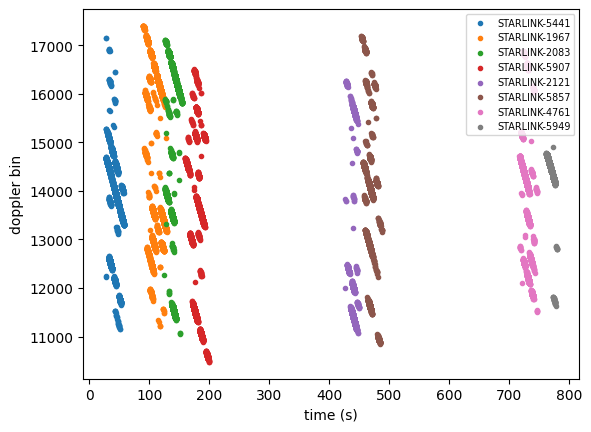

In [3]:
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
sat_num = len(dopp_track_dict[0, :])

plt.figure(2)
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    plt.scatter(t_repeat, dopp_repeat, label=id_dict[0, sat_idx][0], marker='.')
plt.xlabel('time (s)')
plt.ylabel('doppler bin')
plt.legend(fontsize='x-small')
plt.show()

Step 5: Blind ID

Initial number of candidate location clusters: 870


/home/jidazhang/Desktop/new_ws/starlink_ofdm/Starloc/utils/satid_blind_identification.py:212: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Possible: 870
Centroid of group  0 : [ 42.86459045 -99.66385316]
Point that minimizes distance to each satellite trajectory : 42.57314380993937 -100.25312550103015
sats in group: ['STARLINK-1233', 'STARLINK-4755', 'STARLINK-2115', 'STARLINK-5715', 'STARLINK-4746', 'STARLINK-2046', 'STARLINK-5436', 'STARLINK-1201']
Centroid of group  1 : [ 42.82522549 -99.67137135]
Point that minimizes distance to each satellite trajectory : 42.573128314080776 -100.25312685619355
sats in group: ['STARLINK-1233', 'STARLINK-5513', 'STARLINK-2115', 'STARLINK-5715', 'STARLINK-4746', 'STARLINK-2046', 'STARLINK-5436', 'STARLINK-1201']
Centroid of group  2 : [ 42.67989375 -99.96409106]
Point that minimizes distance to each satellite trajectory : 42.394239283168844 -99.93770439553856
sats in group: ['STARLINK-1233', 'STARLINK-4755', 'STARLINK-2115', 'STARLINK-1893', 'STARLINK-4746', 'STARLINK-5726', 'STARLINK-5436', 'STARLINK-1201']
Centroid of group  3 : [ 42.64052879 -99.97160926]
Point that minimizes distanc

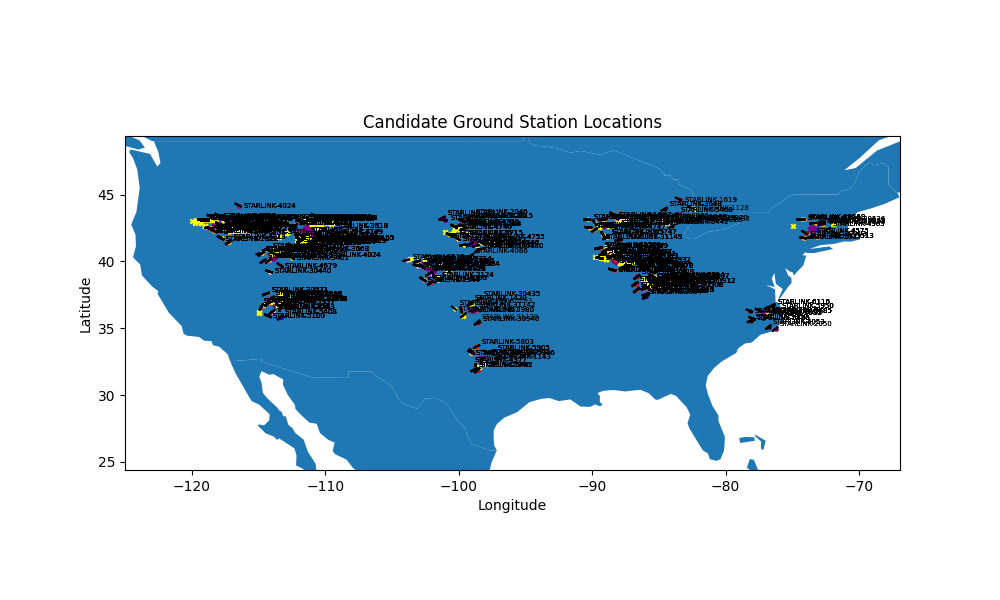

In [4]:
from datetime import datetime
import pytz
start_time_datetime = datetime.fromtimestamp(start_time, tz=pytz.utc)
tle_path = date+'/Starlink.tle'
mat = sio.loadmat(date+'/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
time_arr = [40, 109, 139, 178, 439, 471, 730, 781]
# sort time_arr
time_arr = sorted(time_arr)
%matplotlib widget
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs, get_candidate_locs_jida
search_radius = 200 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs_jida(start_time_datetime, time_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=15)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Candidate Ground Station Locations')
plt.show()

Step 6: Do localization based on phase diff (this part is moved to `recover_orientation.ipynb`)

/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


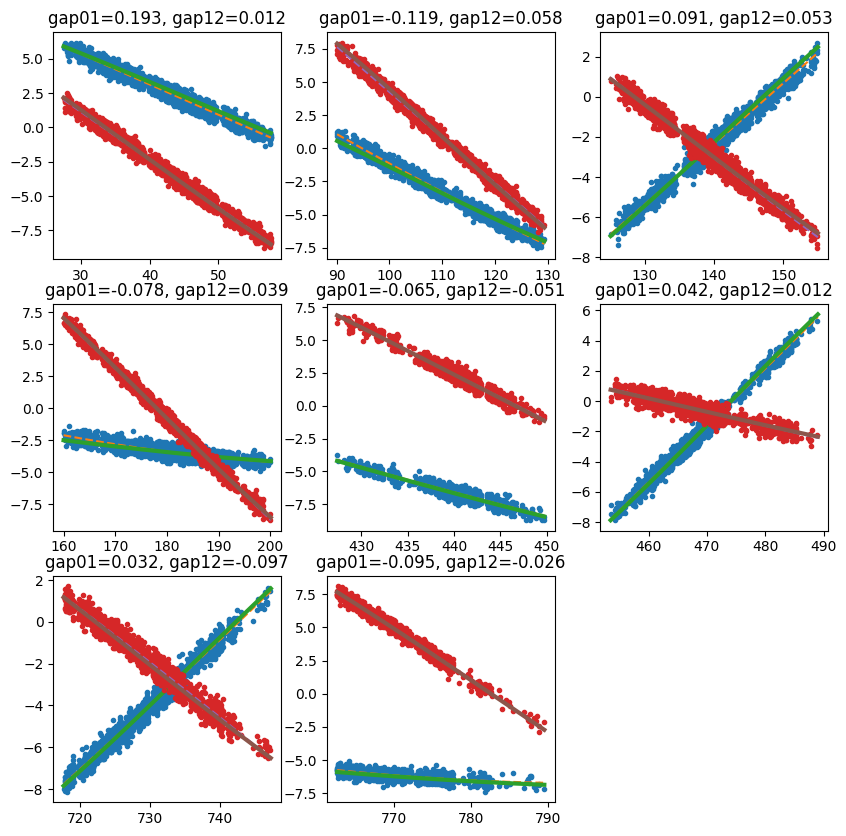

In [14]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 299792458/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# consider orientation - 1: param sweep (not used)
# ang_10_1_opt, ang_10_2_opt = np.deg2rad(np.array([ -0.32732733, -3.        ]))
# ang_12_1_opt, ang_12_2_opt = np.deg2rad(np.array([ 1.48648649, -1.57057057]))
# ang_10_1_opt, ang_10_2_opt = np.deg2rad(np.array([0,0]))
# ang_12_1_opt, ang_12_2_opt = np.deg2rad(np.array([0,0]))
# loc_0 = d * np.array([-np.cos(ang_10_2_opt)*np.sin(ang_10_1_opt), -np.cos(ang_10_2_opt)*np.cos(ang_10_1_opt), -np.sin(ang_10_2_opt)])
# loc_2 = d * np.array([np.cos(ang_12_2_opt)*np.cos(ang_12_1_opt), -np.cos(ang_12_2_opt)*np.sin(ang_12_1_opt), np.sin(ang_12_2_opt)])

# consider orientation - 2: yaw, pitch, roll from imudata
# yaw, pitch, roll = 10.8, -0.243, 1.18 # deg
orient = imu.get_attitude()
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
R = R_yaw @ R_pitch @ R_roll
loc_0, loc_2 = R @ loc_0, R @ loc_2

gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))

    # subtract the ref sig's phase
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]

    # delta phi from measured dopp
    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_

    # use interesct
    # ph_01 = np.array([0.10190301696109838, 0.1072141657100687, 0.15952990824561297, 0.13949102136475666, -0.03849882106260338, 0, 0.30814772628127685, 0.3422352845336718])
    # ph_12 = np.array([-0.3058079427499045, -0.43944649358424215, -0.48449905632332957, -0.5098683305806446, -0.0035030556432502635, 0, -0.19017712557547384, -0.2663338062764069])
    ph_01 = np.array([0.11410881092474234, 0.1070385488338168, 0.1543561913834921, 0.15541238854620687, -0.14857574533419893, 0, 0.26197299754081627, 0.29897558725542694])
    ph_12 = np.array([-0.2777076245784684, -0.44921450272461527, -0.5275005178379573, -0.5060701210567373, 0.005405738105594082, 0, -0.21933156178249558, -0.2697884101030894])

    del_phi_repeat_01 += ph_01[sat_idx]
    del_phi_repeat_12 += ph_12[sat_idx]
    
    # delta phi from simulation
    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

    while np.abs(gap_01-np.mean(gap_01_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01-np.mean(gap_01_arr))
        gap_01 -= tmp
        del_phi_repeat_01 += tmp
    while np.abs(gap_12-np.mean(gap_12_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12-np.mean(gap_12_arr))
        gap_12 -= tmp
        del_phi_repeat_12 += tmp

    # fit the discrete data points with polynomial (second order)
    coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3]))))
    coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4]))))
    del_phi_repeat_01_list.append(del_phi_repeat_01)
    del_phi_repeat_12_list.append(del_phi_repeat_12)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

# plot a large fig
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt', linewidth=3)
    plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt', linewidth=3)
    
    plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
plt.show()

In [15]:
# do grid search
from tqdm import tqdm
x_grid, y_grid = np.linspace(-10e3, 10e3, 300), np.linspace(-10e3, 10e3, 300)
err_min = np.inf
num_sat_for_training = 4
for x in tqdm(x_grid):
    for y in y_grid:
        err = 0
        # add some offset to the ground truth location
        loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
        for sat_idx in range(sat_num):
            t_sim = t_sim_arr[sat_idx]
            mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
            mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
            # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
            # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
            mes_12_diff = np.diff(mes_12)
            mes_01_diff = np.diff(mes_01)
            
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            if sat_idx < num_sat_for_training:
                continue
            err += np.sum(np.abs(mes_12-del_phi_12_gt)) + np.sum(np.abs(mes_01-del_phi_01_gt))
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y])


100%|██████████| 300/300 [00:38<00:00,  7.83it/s]


In [16]:
# print location (in meters)
print(loc_min)
print(np.linalg.norm(loc_min))

[1103.67892977 1772.57525084]
2088.0924787676227
